In [2]:
# ============================================================
# HIERARCHICAL BAYESIAN MAXDIFF MODEL
# ============================================================
# Synthetic example:
#   20 items
#   4 items per MaxDiff task
#   12 tasks per respondent
#   1,000 respondents
#
# Model:
#   respondent utilities ~ hierarchical Normal
#
#   Best:
#       P(best=j) ∝ exp(beta_j)
#
#   Worst conditional on Best:
#       P(worst=j | best) ∝ exp(-beta_j)
#
# Requirements:
#   pip install pymc arviz numpy pandas scipy
# ============================================================

import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import arviz as az
from scipy.special import softmax

# ============================================================
# 1. CONFIGURATION
# ============================================================
SEED = 42
N_RESPONDENTS = 1000
N_ITEMS = 20
ITEMS_PER_TASK = 4
TASKS_PER_RESPONDENT = 12

rng = np.random.default_rng(SEED)

ITEM_NAMES = np.array([f"Feature_{i + 1:02d}"for i in range(N_ITEMS)])

print("=" * 60)
print("HIERARCHICAL BAYESIAN MAXDIFF")
print("=" * 60)
print(f"Respondents:        {N_RESPONDENTS}")
print(f"Items:              {N_ITEMS}")
print(f"Items per task:     {ITEMS_PER_TASK}")
print(f"Tasks/respondent:   {TASKS_PER_RESPONDENT}")

# ============================================================
# 2. GENERATE TRUE POPULATION UTILITIES
# ============================================================
# These are unknown in a real study.
#
# We generate them here so that after fitting the model,
# we can test whether HB recovers the truth.
# ============================================================

true_mu = rng.normal(loc=0,scale=0.8,size=N_ITEMS)

# ------------------------------------------------------------
# Identification
# MaxDiff utilities are relative.
# Therefore:
#       sum(mu) = 0
# ------------------------------------------------------------

true_mu = (true_mu- true_mu.mean())

# ============================================================
# 3. RESPONDENT HETEROGENEITY
# ============================================================
# Different respondents have different preferences.
# sigma_j controls heterogeneity for feature j.
# ============================================================

true_sigma = rng.uniform(low=0.30,high=0.70,size=N_ITEMS)

# ============================================================
# 4. GENERATE RESPONDENT-LEVEL UTILITIES
# ============================================================

true_beta = (true_mu[None, :]+ rng.normal(loc=0,scale=true_sigma,size=(N_RESPONDENTS,N_ITEMS)))

# ------------------------------------------------------------
# Center each respondent's utilities
# Again, only relative utilities matter.
# ------------------------------------------------------------

true_beta = (true_beta- true_beta.mean(axis=1,keepdims=True))
true_table = pd.DataFrame(
    {
    "feature":ITEM_NAMES,
    "true_utility":true_mu,
    "true_sigma":true_sigma
    }).sort_values("true_utility",ascending=False)

print("\nTrue population utilities:")
print(true_table.to_string(index=False))

# ============================================================
# 5. SIMULATE MAXDIFF SURVEY
# ============================================================
# Each respondent receives 12 questions.
# Each question contains 4 items.
# Respondent chooses:
#       BEST
# then:
#       WORST among remaining three.
# ============================================================

records = []

for respondent in range(N_RESPONDENTS):
    for task in range(TASKS_PER_RESPONDENT):
        # ----------------------------------------------------
        # Select four unique items
        # ----------------------------------------------------
        choice_set = rng.choice(N_ITEMS,size=ITEMS_PER_TASK,replace=False)

        # ----------------------------------------------------
        # Respondent utilities for those items
        # ----------------------------------------------------
        utilities = true_beta[respondent,choice_set]

        # ====================================================
        # BEST
        # ====================================================
        best_probabilities = softmax(utilities)
        best_position = rng.choice(ITEMS_PER_TASK,p=best_probabilities)
        best_item = choice_set[best_position]

        # ====================================================
        # WORST CONDITIONAL ON BEST
        # ====================================================
        remaining_positions = np.array([position
            for position in range(
                ITEMS_PER_TASK
            )
            if position != best_position
        ])
        remaining_utilities = utilities[remaining_positions]

        # Lower utility = more likely worst
        worst_probabilities = softmax(-remaining_utilities)
        worst_relative_position = (rng.choice(len(remaining_positions),p=worst_probabilities))
        worst_position = (remaining_positions[worst_relative_position])
        worst_item = choice_set[worst_position]

        # ----------------------------------------------------
        # Store observation
        # ----------------------------------------------------
        record = {
            "respondent_id":respondent,
            "task":task,
            "best_position":best_position,
            "worst_position":worst_position,
            "best_item":best_item,
            "worst_item":worst_item}

        # Store each displayed item
        for position in range(ITEMS_PER_TASK):
            record[f"item_{position + 1}"] = choice_set[position]
        records.append(record)
df = pd.DataFrame(records)

# print("\nExample survey responses:")
# print(df.head())
print("\nTotal MaxDiff tasks:",len(df))

# ============================================================
# 6. CREATE MODEL ARRAYS
# ============================================================
respondent_idx = (df["respondent_id"].to_numpy(dtype="int32"))
item_columns = [f"item_{i + 1}"for i in range(ITEMS_PER_TASK)]
choice_sets = (df[item_columns].to_numpy(dtype="int32"))
best_positions = (df["best_position"].to_numpy(dtype="int32"))
worst_positions = (df["worst_position"].to_numpy(dtype="int32"))
N_OBSERVATIONS = len(df)

print("\nNumber of observations:",N_OBSERVATIONS)

# ============================================================
# 7. HIERARCHICAL BAYESIAN MODEL
# ============================================================
with pm.Model() as maxdiff_model:

    # ========================================================
    # POPULATION MEAN UTILITIES
    # ========================================================
    mu_raw = pm.Normal("mu_raw",mu=0,sigma=1,shape=N_ITEMS)

    # --------------------------------------------------------
    # Zero-sum identification constraint
    # --------------------------------------------------------
    mu = pm.Deterministic("mu",mu_raw- pt.mean(mu_raw))

    # ========================================================
    # POPULATION HETEROGENEITY
    # ========================================================
    sigma = pm.HalfNormal("sigma",sigma=0.75,shape=N_ITEMS)

    # ========================================================
    # RESPONDENT-LEVEL UTILITIES
    # Non-centered parameterization:
    # beta_rj =
    #       mu_j
    #       +
    #       sigma_j * z_rj
    # ========================================================
    z = pm.Normal("z",mu=0,sigma=1,shape=(N_RESPONDENTS,N_ITEMS))
    beta_raw = (mu[None, :]+z* sigma[None, :])

    # --------------------------------------------------------
    # Center each respondent's utilities
    # --------------------------------------------------------
    beta = pm.Deterministic("beta",beta_raw- pt.mean(beta_raw,axis=1,keepdims=True))

    # ========================================================
    # UTILITIES FOR ITEMS SHOWN IN EACH QUESTION
    # ========================================================
    # Result shape:
    #       observations × items_per_task
    #       12,000 × 4
    # ========================================================
    task_utilities = beta[respondent_idx[:, None],choice_sets]

    # ========================================================
    # BEST LIKELIHOOD
    # ========================================================
    # PyMC Categorical expects:
    #       p=
    # OR
    #       logit_p=
    # NOT logits=
    # ========================================================
    pm.Categorical("best_choice",logit_p=task_utilities,observed=best_positions)

    # ========================================================
    # WORST LIKELIHOOD
    # ========================================================
    # We condition on the observed BEST choice.
    #
    # The selected BEST alternative is removed from
    # consideration for WORST.
    # Remaining alternatives receive logits:
    #       -utility
    # ========================================================

    # --------------------------------------------------------
    # Position indices:
    # [[0, 1, 2, 3]]
    # --------------------------------------------------------
    position_index = (pt.arange(ITEMS_PER_TASK)[None, :])

    # --------------------------------------------------------
    # Mask the observed BEST position
    # --------------------------------------------------------
    best_mask = pt.eq(position_index,best_positions[:, None])

    # --------------------------------------------------------
    # Worst logits
    # BEST receives huge negative value,
    # effectively probability zero.
    # Other alternatives use -utility.
    # --------------------------------------------------------
    worst_logit_p = pt.where(best_mask,-1e9,-task_utilities)

    # --------------------------------------------------------
    # WORST categorical likelihood
    # --------------------------------------------------------
    pm.Categorical("worst_choice",logit_p=worst_logit_p,observed=worst_positions)

# ============================================================
# 8. INSPECT MODEL
# ============================================================
print("\nModel:")
print(maxdiff_model)

# ============================================================
# 9. SAMPLE POSTERIOR
# ============================================================
# IMPORTANT:
# 1,000 respondents × 20 respondent utilities creates
# 20,000 latent respondent effects.
#
# This is therefore a substantial model.
# For your FIRST TEST you may want:
#       N_RESPONDENTS = 100
# and:
#       draws=500
#       tune=500
# before running the full 1,000-person model.
#
# ============================================================

with maxdiff_model: trace = pm.sample(
    draws=1000,
    tune=1000,
    chains=4,
    cores=4,
    target_accept=0.90,
    random_seed=SEED,
    return_inferencedata=True
    )

# ============================================================
# 10. CONVERGENCE DIAGNOSTICS
# ============================================================
diagnostics = az.summary(trace,var_names=["mu","sigma"],ci_prob=0.95)

print("\nConvergence diagnostics:")
print(diagnostics)

# ============================================================
# 11. EXTRACT POPULATION POSTERIOR
# ============================================================
mu_posterior = (trace.posterior["mu"].stack(sample=("chain","draw")).values)

# Shape:N_ITEMS × posterior samples
estimated_mu = (mu_posterior.mean(axis=1))
lower_95 = np.quantile(mu_posterior,0.025,axis=1)
upper_95 = np.quantile(mu_posterior,0.975,axis=1)

# ============================================================
# 12. POPULATION RESULTS
# ============================================================
population_results = pd.DataFrame({
    "feature":ITEM_NAMES,
    "estimated_utility":estimated_mu,
    "lower_95":lower_95,
    "upper_95":upper_95,
    "true_utility":true_mu
    })
population_results = (population_results.sort_values("estimated_utility",ascending=False).reset_index(drop=True))
population_results["rank"] = np.arange(1,N_ITEMS + 1)

print("\nPopulation utility estimates:")
print(population_results.to_string(index=False))

# ============================================================
# 13. RESPONDENT-LEVEL UTILITIES
# ============================================================
beta_posterior_mean = (trace.posterior["beta"].mean(dim=("chain","draw")).values)
respondent_results = pd.DataFrame(beta_posterior_mean,columns=ITEM_NAMES)
respondent_results.insert(0,"respondent_id",np.arange(N_RESPONDENTS))

print("\nRespondent-level utilities:")
print(respondent_results.head())

# ============================================================
# 14. SYNTHETIC RECOVERY TEST
# ============================================================
# Because this is simulated data, we know the true utilities.
# This lets us test whether the HB model recovered them.
# ============================================================
recovery_correlation = np.corrcoef(true_mu,estimated_mu)[0, 1]
rmse = np.sqrt(np.mean((true_mu- estimated_mu) ** 2))

print("\nMODEL RECOVERY")
print("Correlation:",round(recovery_correlation,4))
print("RMSE:",round(rmse,4))


# ============================================================
# 15. RANK CORRELATION
# ============================================================

from scipy.stats import spearmanr

rank_correlation = spearmanr(true_mu,estimated_mu).statistic
print("Spearman rank correlation:",round(rank_correlation,4))

# ============================================================
# 16. TRANSFORM UTILITIES TO 100-POINT SHARE SCALE
# ============================================================
# Useful for reporting.
# IMPORTANT:
# This is NOT:
#       "% of respondents choosing the feature"
# It is simply a softmax transformation of utilities.
# ============================================================

exp_utility = np.exp(estimated_mu- np.max(estimated_mu))
preference_share = (100* exp_utility/ exp_utility.sum())
share_results = pd.DataFrame({
    "feature":
        ITEM_NAMES,
    "utility":
        estimated_mu,
    "preference_share":
        preference_share
})
share_results = (share_results.sort_values("preference_share",ascending=False).reset_index(drop=True))

print("\nPreference-share transformation:")
print(share_results.to_string(index=False))

# ============================================================
# 17. SIMPLE CONVERGENCE CHECKS
# ============================================================
max_rhat = (diagnostics["r_hat"].max())
min_ess_bulk = (diagnostics["ess_bulk"].min())

print("\nSAMPLING DIAGNOSTICS")
print("Maximum R-hat:",max_rhat)
print("Minimum bulk ESS:",min_ess_bulk)

if max_rhat < 1.01:
    print("R-hat check: PASS")
else:
    print("R-hat check: INVESTIGATE")


# ============================================================
# 18. SAVE OUTPUTS
# ============================================================

df.to_csv("synthetic_maxdiff_responses.csv",index=False)
population_results.to_csv("hb_maxdiff_population_utilities.csv",index=False)
respondent_results.to_csv("hb_maxdiff_respondent_utilities.csv",index=False)
share_results.to_csv("hb_maxdiff_preference_shares.csv",index=False)
diagnostics.to_csv("hb_maxdiff_diagnostics.csv")
print("\nFiles saved successfully.")

HIERARCHICAL BAYESIAN MAXDIFF
Respondents:        1000
Items:              20
Items per task:     4
Tasks/respondent:   12

True population utilities:
   feature  true_utility  true_sigma
Feature_14      0.928139    0.448184
Feature_04      0.778797    0.657248
Feature_11      0.729864    0.597905
Feature_19      0.729106    0.390764
Feature_12      0.648579    0.687004
Feature_03      0.626707    0.688279
Feature_15      0.400353    0.487822
Feature_17      0.321346    0.351969
Feature_01      0.270119    0.603235
Feature_07      0.128618    0.486688
Feature_13      0.079170    0.430330
Feature_09      0.012905    0.361716
Feature_20     -0.013595    0.567926
Feature_08     -0.226648    0.317522
Feature_10     -0.656089    0.573220
Feature_16     -0.661088    0.375789
Feature_18     -0.740760    0.490282
Feature_02     -0.805642    0.441810
Feature_06     -1.015398    0.377855
Feature_05     -1.534482    0.611353

Total MaxDiff tasks: 12000

Number of observations: 12000

Model:


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_raw, sigma, z]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 209 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details



Convergence diagnostics:
             mean     sd eti95_lb eti95_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
mu[0]        0.25  0.039     0.17     0.33     4704     3163  1.00   0.00058  0.00064
mu[1]      -0.814  0.041     -0.9    -0.73     4018     2840  1.00   0.00065  0.00067
mu[2]       0.628  0.044     0.54     0.71     4272     3309  1.00   0.00067  0.00066
mu[3]       0.758  0.043     0.67     0.84     4946     3265  1.00   0.00061  0.00067
mu[4]       -1.52  0.047     -1.6     -1.4     3940     3030  1.00   0.00075   0.0006
mu[5]      -0.973  0.038       -1     -0.9     4021     2677  1.00    0.0006  0.00059
mu[6]       0.136  0.039     0.06     0.21     4489     3020  1.00   0.00058  0.00058
mu[7]      -0.231  0.036     -0.3    -0.16     3949     2787  1.00   0.00057  0.00057
mu[8]       -0.01  0.036   -0.081    0.062     4396     2770  1.00   0.00055   0.0006
mu[9]      -0.576  0.041    -0.66    -0.49     4402     2985  1.00   0.00062  0.00065
mu[10]      0.717  0.043    

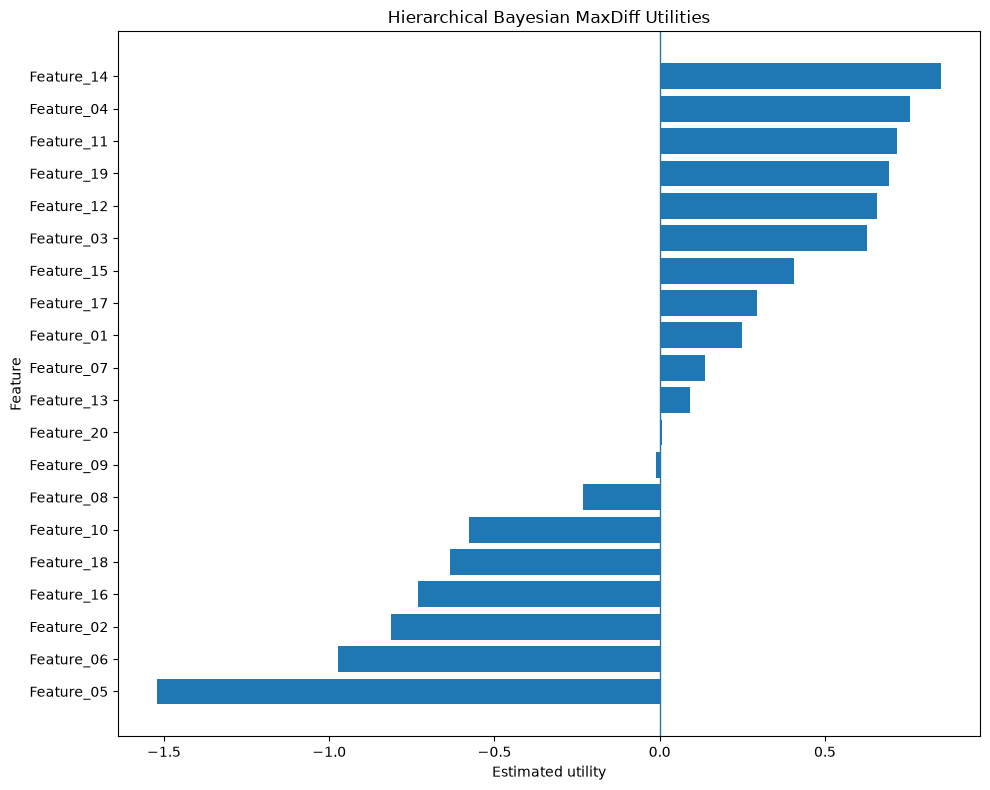

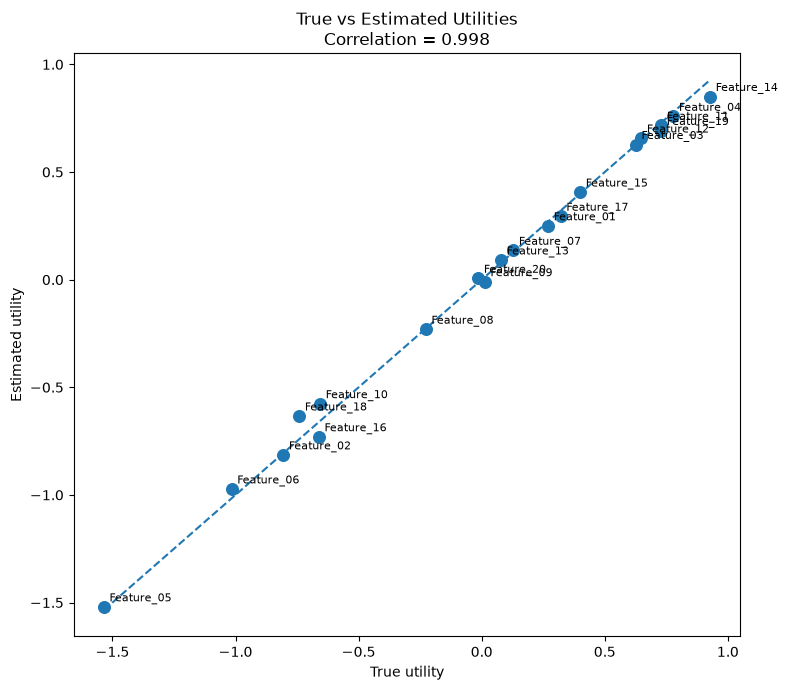

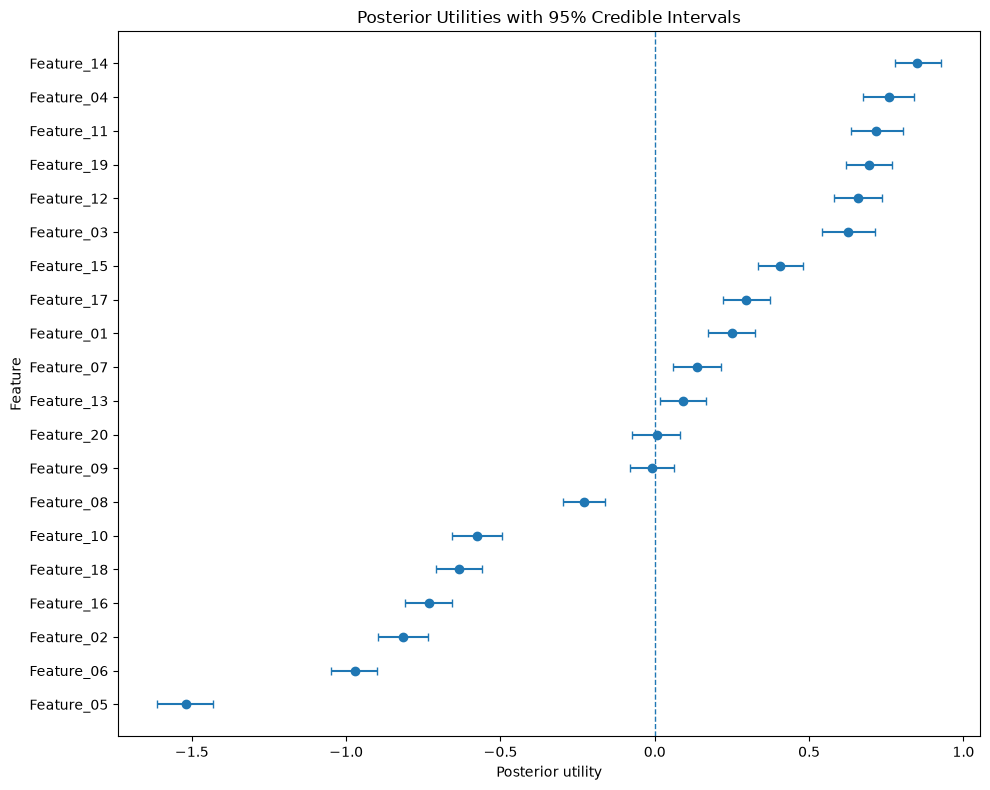

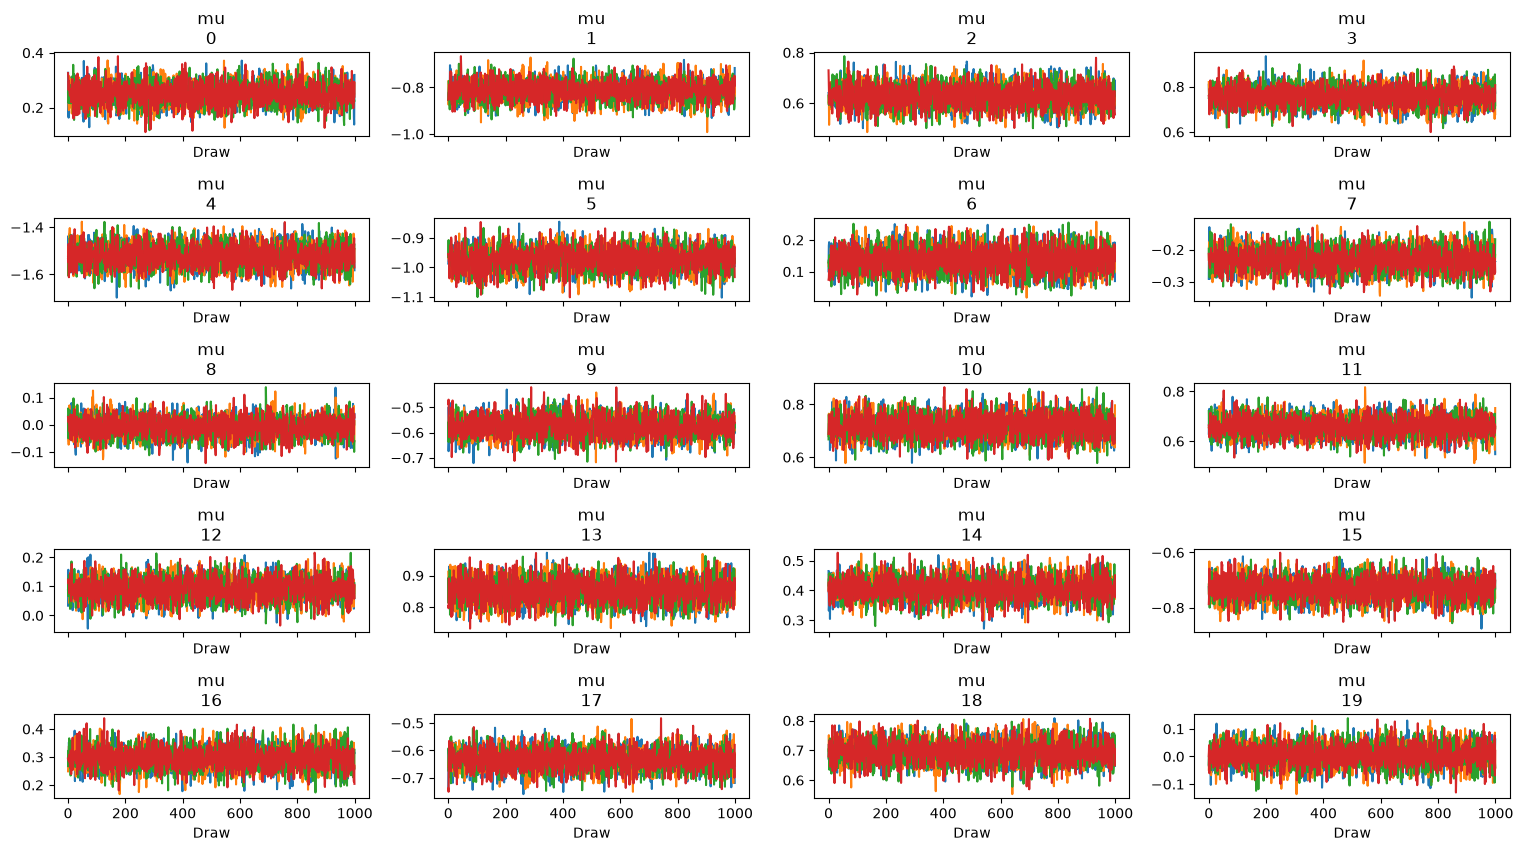

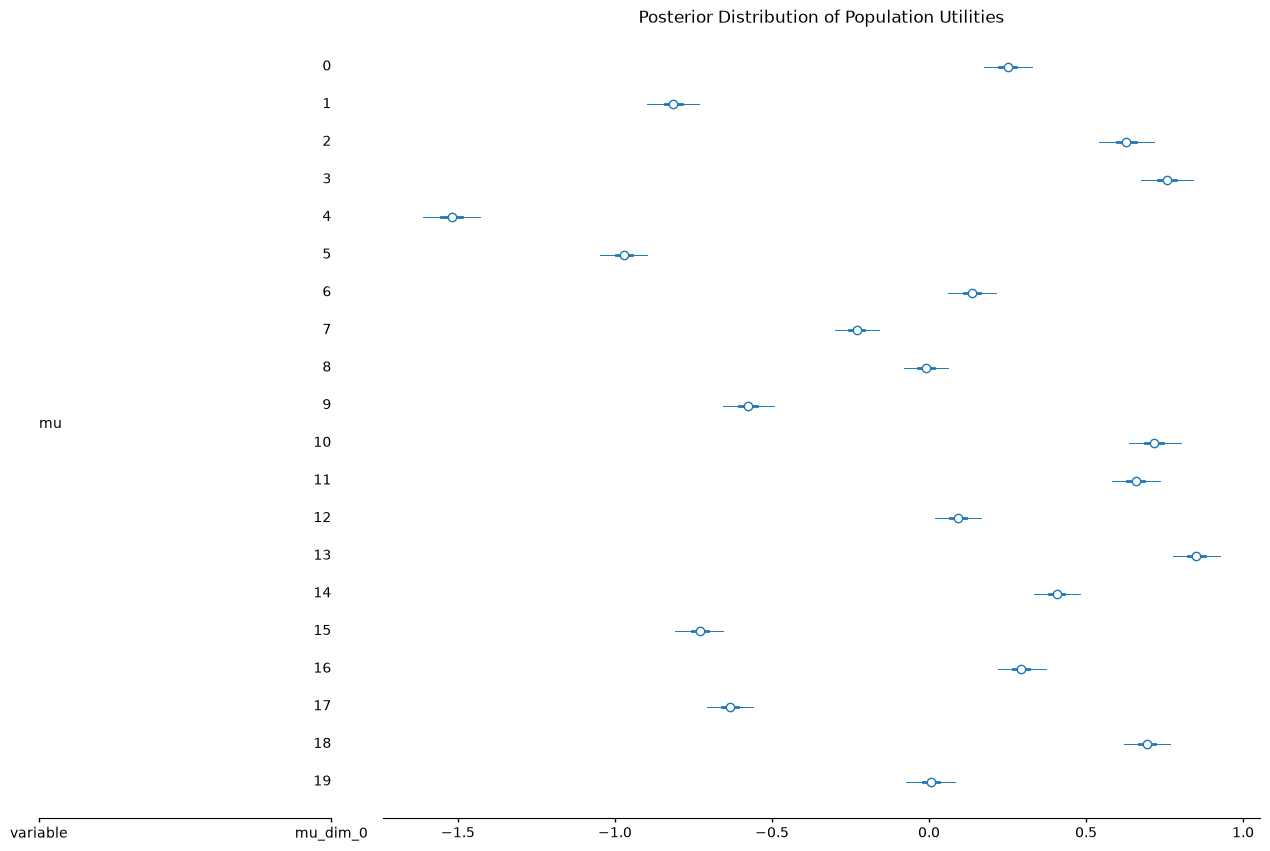

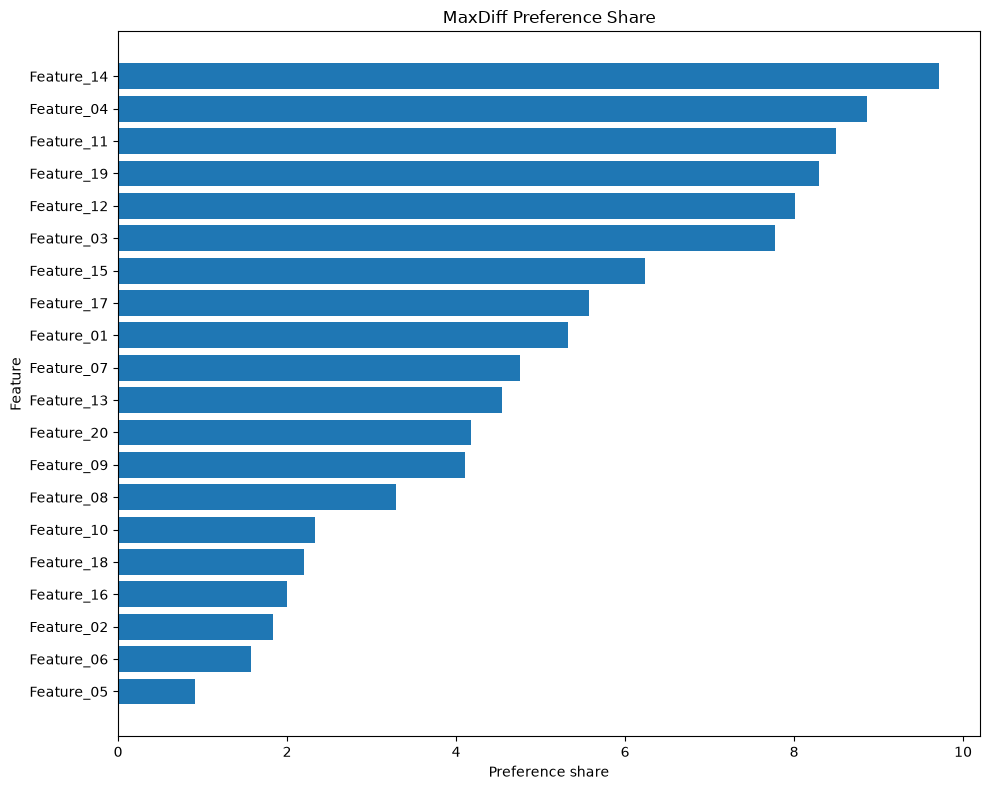

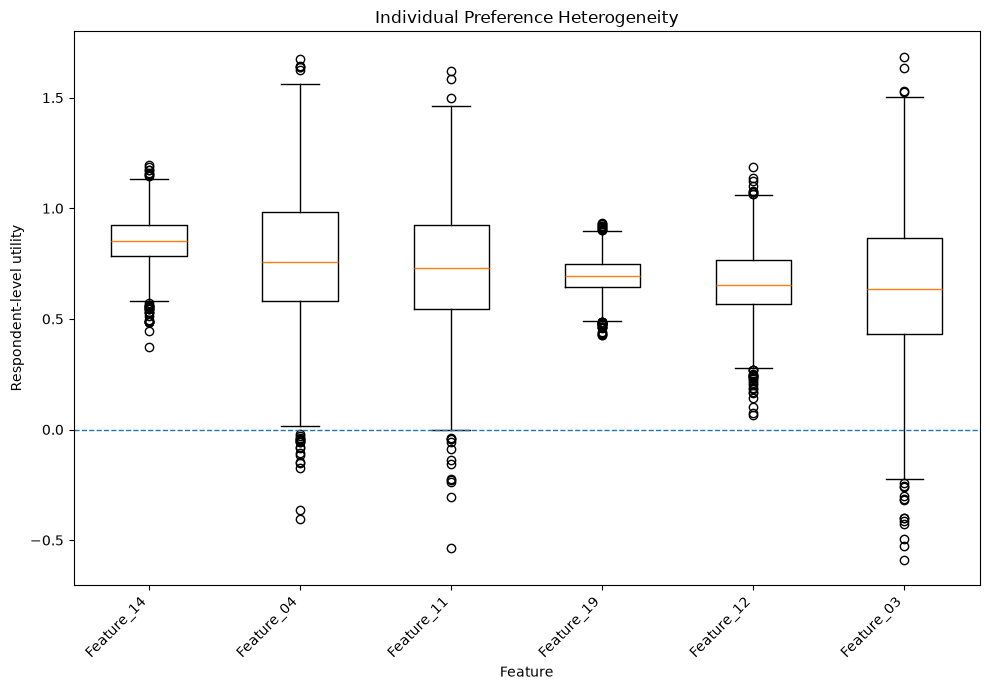

In [7]:
# ============================================================
# 19. VISUALIZATIONS
# ============================================================
import matplotlib.pyplot as plt

# ============================================================
# GRAPH 1
# POPULATION-LEVEL ESTIMATED UTILITIES
# ============================================================
plot_df = (population_results.sort_values("estimated_utility",ascending=True))
plt.figure(figsize=(10, 8))
plt.barh(plot_df["feature"],plot_df["estimated_utility"])
plt.axvline(0,linewidth=1)
plt.xlabel("Estimated utility")
plt.ylabel("Feature")
plt.title("Hierarchical Bayesian MaxDiff Utilities")
plt.tight_layout()
plt.show()

# ============================================================
# GRAPH 2
# TRUE VS ESTIMATED UTILITIES
#
# Only available for synthetic data because in a real survey
# we obviously do not know the true utilities.
# ============================================================
plt.figure(figsize=(8, 7))
plt.scatter(true_mu,estimated_mu,s=70)

# Perfect-recovery reference line
minimum = min(true_mu.min(),estimated_mu.min())
maximum = max(true_mu.max(),estimated_mu.max())
plt.plot([minimum, maximum],[minimum, maximum],linestyle="--")

# Label each feature
for i in range(N_ITEMS):
    plt.annotate(ITEM_NAMES[i],
        (
            true_mu[i],
            estimated_mu[i]
        ),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.xlabel("True utility")
plt.ylabel("Estimated utility")
plt.title(f"True vs Estimated Utilities\n"f"Correlation = {recovery_correlation:.3f}")
plt.tight_layout()
plt.show()

# ============================================================
# GRAPH 3
# POSTERIOR 95% CREDIBLE INTERVALS
# ============================================================
interval_df = (population_results.sort_values("estimated_utility",ascending=True).reset_index(drop=True))
y_position = np.arange(len(interval_df))
lower_error = (interval_df["estimated_utility"]- interval_df["lower_95"])
upper_error = (interval_df["upper_95"]- interval_df["estimated_utility"])
plt.figure(figsize=(10, 8))
plt.errorbar(
    interval_df["estimated_utility"],
    y_position,
    xerr=[
        lower_error,upper_error
        ],
    fmt="o",capsize=3
    )
plt.yticks(y_position,interval_df["feature"])
plt.axvline(0,linewidth=1,linestyle="--")
plt.xlabel("Posterior utility")
plt.ylabel("Feature")
plt.title("Posterior Utilities with 95% Credible Intervals")
plt.tight_layout()
plt.show()

# ============================================================
# GRAPH 4
# MCMC TRACE PLOTS
#
# Very important diagnostic.
# This lets you see whether the chains mixed properly.
# ============================================================
az.plot_trace(trace,var_names=["mu"])
plt.tight_layout()
plt.show()

# ============================================================
# GRAPH 5
# POSTERIOR DISTRIBUTIONS OF POPULATION UTILITIES
# ============================================================
az.plot_forest(trace,var_names=["mu"],combined=True,ci_probs=(0.50, 0.95))
plt.title("Posterior Distribution of Population Utilities")
plt.tight_layout()
plt.show()

# ============================================================
# GRAPH 6
# PREFERENCE-SHARE TRANSFORMATION
# ============================================================
share_plot = (share_results.sort_values("preference_share",ascending=True))

plt.figure(figsize=(10, 8))
plt.barh(share_plot["feature"],share_plot["preference_share"])
plt.xlabel("Preference share")
plt.ylabel("Feature")
plt.title("MaxDiff Preference Share")
plt.tight_layout()
plt.show()

# ============================================================
# GRAPH 7
# RESPONDENT-LEVEL HETEROGENEITY
#
# Shows how individual preferences vary around the
# population-level estimate.
# ============================================================

# Select the 6 highest-ranked features to keep
# the graph readable.
top_features = (population_results.head(6)["feature"].tolist())
heterogeneity_data = [respondent_results[feature].values for feature in top_features]

plt.figure(figsize=(10, 7))
plt.boxplot(heterogeneity_data, tick_labels=top_features)
plt.axhline(0,linewidth=1,linestyle="--")
plt.ylabel("Respondent-level utility")
plt.xlabel("Feature")
plt.title("Individual Preference Heterogeneity")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()